In [15]:
from qiskit import QuantumCircuit


In [16]:
# Circuit A: One X gate
circuit_a = QuantumCircuit(1, 1)
circuit_a.x(0)
circuit_a.measure(0, 0)

In [17]:
# Circuit B: Two X gates
circuit_b = QuantumCircuit(1, 1)
circuit_b.x(0)
circuit_b.x(0)
circuit_b.measure(0, 0)

In [18]:
# Circuit C: One H gate
circuit_c = QuantumCircuit(1, 1)
circuit_c.h(0)
circuit_c.measure(0, 0)

Circuit A: One X gate


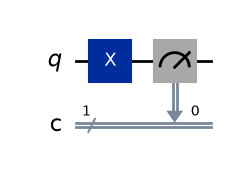

In [19]:
# Display all three circuits
print("Circuit A: One X gate")
display(circuit_a.draw("mpl"))

Circuit B: Two X gates


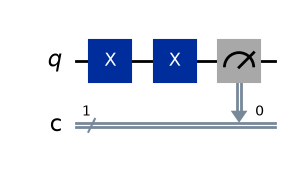

In [20]:
print("Circuit B: Two X gates")
display(circuit_b.draw("mpl"))

Circuit C: One H gate


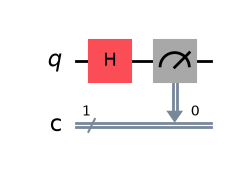

In [21]:
print("Circuit C: One H gate")
display(circuit_c.draw("mpl"))


In [38]:
%matplotlib inline
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt


In [39]:

predictions = {
    "Circuit A": {"0": 0, "1": 100},
    "Circuit B": {"0": 100, "1": 0},
    "Circuit C": {"0": 50, "1": 50}
}

print("PREDICTIONS BEFORE EXECUTION")
print("Circuit A: 100% outcome 1")
print("Circuit B: 100% outcome 0")
print("Circuit C: Approximately 50% outcome 0 and 50% outcome 1")


PREDICTIONS BEFORE EXECUTION
Circuit A: 100% outcome 1
Circuit B: 100% outcome 0
Circuit C: Approximately 50% outcome 0 and 50% outcome 1


In [40]:

backend = AerSimulator()

circuits = [circuit_a, circuit_b, circuit_c]
names = ["Circuit A", "Circuit B", "Circuit C"]

results = {}

for name, circuit in zip(names, circuits):
    compiled_circuit = transpile(circuit, backend)
    job = backend.run(compiled_circuit, shots=100)
    counts = job.result().get_counts()

    # Include outcomes with zero counts
    counts = {
        "0": counts.get("0", 0),
        "1": counts.get("1", 0)
    }

    results[name] = counts

    print(f"\n{name}")
    print("Measurement results:", counts)
    print("Number of shots:", sum(counts.values()))



Circuit A
Measurement results: {'0': 0, '1': 100}
Number of shots: 100

Circuit B
Measurement results: {'0': 100, '1': 0}
Number of shots: 100

Circuit C
Measurement results: {'0': 44, '1': 56}
Number of shots: 100


In [41]:

print("PREDICTION VS ACTUAL RESULTS\n")

for name in names:
    predicted = predictions[name]
    actual = results[name]

    print(name)
    print(f"Predicted 0: {predicted['0']}, Actual 0: {actual['0']}")
    print(f"Predicted 1: {predicted['1']}, Actual 1: {actual['1']}")

    if name == "Circuit A":
        print("Comparison: The X gate should always produce 1.")
    elif name == "Circuit B":
        print("Comparison: Two X gates should return the qubit to 0.")
    else:
        print("Comparison: The H gate should produce approximately equal counts of 0 and 1.")

    print("-" * 40)


PREDICTION VS ACTUAL RESULTS

Circuit A
Predicted 0: 0, Actual 0: 0
Predicted 1: 100, Actual 1: 100
Comparison: The X gate should always produce 1.
----------------------------------------
Circuit B
Predicted 0: 100, Actual 0: 100
Predicted 1: 0, Actual 1: 0
Comparison: Two X gates should return the qubit to 0.
----------------------------------------
Circuit C
Predicted 0: 50, Actual 0: 44
Predicted 1: 50, Actual 1: 56
Comparison: The H gate should produce approximately equal counts of 0 and 1.
----------------------------------------


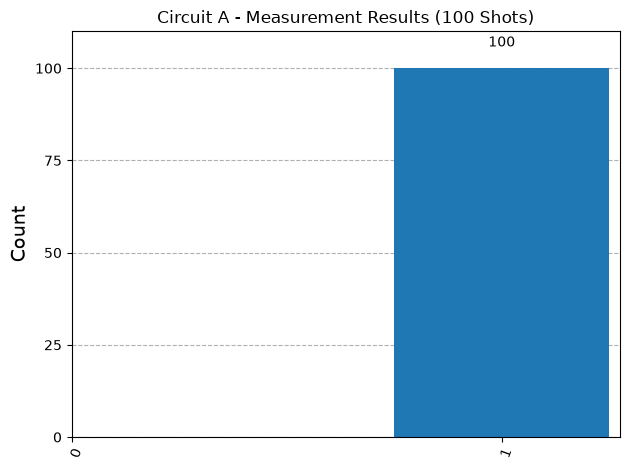

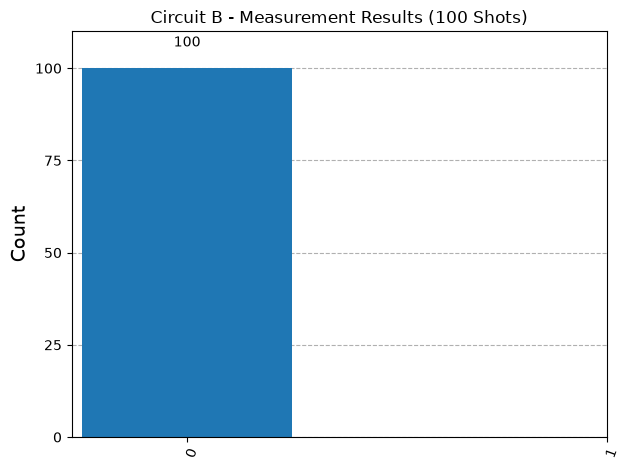

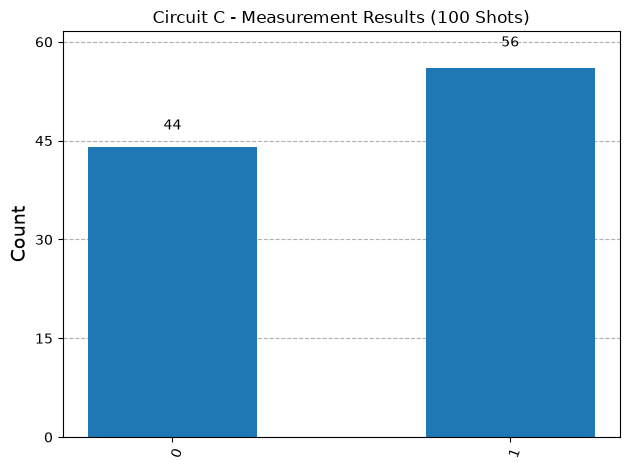

In [42]:
# Display histograms for all three circuits

for name in names:
    plot_histogram(
        results[name],
        title=f"{name} - Measurement Results (100 Shots)"
    )
    plt.show()